<a href="https://colab.research.google.com/github/parvathy10/Learning-PyTorch-/blob/main/Assignment_2_Insurance_Cost_Prediction_using_Linear_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import torch
import torchvision
import torch.nn as nn
import pandas as pd
import matplotlib.pyplot as plt
import torch.nn.functional as F

from torchvision.datasets.utils import download_url
from torch.utils.data import DataLoader, TensorDataset, random_split

In [4]:
DATASET_URL = "https://raw.githubusercontent.com/JovianHQ/notebooks/refs/heads/main/deep-learning-with-pytorch-zero-to-gans/assignment-2-train-your-first-model/insurance.csv"

DATA_FILENAME = "insurance.csv"

download_url(DATASET_URL, '.')

100%|██████████| 55.6k/55.6k [00:00<00:00, 18.9MB/s]


In [5]:
dataframe_raw = pd.read_csv(DATA_FILENAME)

dataframe_raw.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## Step 1: Download and Explore the Dataset

### Objective
The objective of this step is to download the medical insurance dataset and explore its contents before preparing it for Machine Learning.

### Libraries used
- PyTorch: Used for tensor operations and model development.
- Pandas: Used to load and manipulate tabular data.
- Matplotlib: Used for data visualisation.
- Torch utilities: Used for downloading and preparing the dataset.

### Dataset loading
The dataset is available in CSV (Comma-Separated Values) format. It is downloaded using the `download_url()` function and loaded into a Pandas DataFrame using `pd.read_csv()`.

### DataFrame
A DataFrame is a two-dimensional tabular structure consisting of rows and columns. The `head()` function displays the first five rows of the dataset.

### Initial observation
The dataset contains information about age, sex, BMI, children, smoking habits, region and medical insurance charges.

The insurance charges column is the target variable that we want our Linear Regression model to predict.

In [6]:
your_name = "Parvathy"

In [7]:
def customize_dataset(dataframe_raw, rand_str):

    dataframe = dataframe_raw.copy(deep=True)

    # Drop some rows
    dataframe = dataframe.sample(
        int(0.95 * len(dataframe)),
        random_state=int(ord(rand_str[0]))
    )

    # Scale input
    dataframe.bmi = dataframe.bmi * ord(rand_str[1])/100.

    # Scale target
    dataframe.charges = dataframe.charges * ord(rand_str[2])/100.

    # Drop column
    if ord(rand_str[3]) % 2 == 1:
        dataframe = dataframe.drop(['region'], axis=1)

    return dataframe

In [8]:
dataframe = customize_dataset(dataframe_raw, your_name)

dataframe.head()

,age,sex,bmi,children,smoker,region,charges
240,23,female,35.5699,2,yes,northeast,43903.256262
651,53,female,38.4120,1,no,southeast,12060.870540
761,23,male,34.1440,1,no,southwest,2755.328700
836,36,male,30.5550,0,no,southwest,5018.545620
1147,20,female,30.9624,0,no,northwest,2578.188432


In [9]:
def dataframe_to_arrays(dataframe):
    dataframe1 = dataframe.copy(deep=True)

    for col in categorical_cols:
        dataframe1[col] = dataframe1[col].astype('category').cat.codes

    inputs_array = dataframe1[input_cols].to_numpy()
    targets_array = dataframe1[output_cols].to_numpy()

    return inputs_array, targets_array

In [10]:
input_cols = ['age', 'sex', 'bmi', 'children', 'smoker', 'region']

categorical_cols = ['sex', 'smoker', 'region']

output_cols = ['charges']

In [11]:
inputs_array, targets_array = dataframe_to_arrays(dataframe)

inputs_array, targets_array

(array([[23.     ,  0.     , 35.5699 ,  2.     ,  1.     ,  0.     ],
        [53.     ,  0.     , 38.412  ,  1.     ,  0.     ,  2.     ],
        [23.     ,  1.     , 34.144  ,  1.     ,  0.     ,  3.     ],
        ...,
        [59.     ,  0.     , 35.66205,  1.     ,  1.     ,  0.     ],
        [53.     ,  0.     , 32.2525 ,  0.     ,  0.     ,  0.     ],
        [48.     ,  0.     , 32.3301 ,  0.     ,  0.     ,  2.     ]],
       shape=(1271, 6)),
 array([[43903.256262],
        [12060.87054 ],
        [ 2755.3287  ],
        ...,
        [54602.342139],
        [12043.96833 ],
        [ 9443.395998]], shape=(1271, 1)))

In [12]:
inputs = torch.tensor(inputs_array, dtype=torch.float32)

targets = torch.tensor(targets_array, dtype=torch.float32)

inputs.dtype, targets.dtype

(torch.float32, torch.float32)

In [13]:
dataset = TensorDataset(inputs, targets)

In [14]:
num_rows = len(dataframe)

print(num_rows)

1271


In [15]:
val_percent = 0.15

val_size = int(num_rows * val_percent)

train_size = num_rows - val_size

train_ds, val_ds = random_split(
    dataset,
    [train_size, val_size]
)

In [16]:
print("Total samples:", num_rows)
print("Training samples:", len(train_ds))
print("Validation samples:", len(val_ds))

Total samples: 1271
Training samples: 1081
Validation samples: 190


In [17]:
batch_size = 64

train_loader = DataLoader(
    train_ds,
    batch_size,
    shuffle=True
)

val_loader = DataLoader(
    val_ds,
    batch_size
)

In [18]:
for xb, yb in train_loader:
    print("inputs:", xb)
    print("targets:", yb)
    break

inputs: tensor([[59.0000,  0.0000, 35.4244,  1.0000,  0.0000,  2.0000],
        [42.0000,  1.0000, 25.5256,  1.0000,  0.0000,  1.0000],
        [45.0000,  0.0000, 38.7952,  3.0000,  0.0000,  0.0000],
        [64.0000,  0.0000, 22.3003,  0.0000,  1.0000,  2.0000],
        [37.0000,  1.0000, 45.1341,  3.0000,  0.0000,  2.0000],
        [41.0000,  1.0000, 33.1740,  2.0000,  0.0000,  1.0000],
        [18.0000,  1.0000, 33.3971,  0.0000,  0.0000,  2.0000],
        [19.0000,  1.0000, 26.7720,  0.0000,  0.0000,  3.0000],
        [61.0000,  1.0000, 35.0170,  3.0000,  0.0000,  3.0000],
        [27.0000,  1.0000, 25.2491,  0.0000,  0.0000,  0.0000],
        [50.0000,  1.0000, 25.6177,  0.0000,  0.0000,  1.0000],
        [50.0000,  1.0000, 31.2388,  0.0000,  0.0000,  1.0000],
        [19.0000,  0.0000, 30.8703,  1.0000,  0.0000,  1.0000],
        [41.0000,  0.0000, 31.2340,  1.0000,  0.0000,  3.0000],
        [21.0000,  1.0000, 34.4641,  0.0000,  0.0000,  2.0000],
        [31.0000,  0.0000, 28.38

In [19]:
print("Input batch shape:", xb.shape)
print("Target batch shape:", yb.shape)

Input batch shape: torch.Size([64, 6])
Target batch shape: torch.Size([64, 1])


In [20]:
input_size = len(input_cols)
output_size = len(output_cols)

print(input_size, output_size)

6 1


In [21]:
class InsuranceModel(nn.Module):

    def __init__(self):
        super().__init__()
        self.linear = nn.Linear(input_size, output_size)

    def forward(self, xb):
        out = self.linear(xb)
        return out

    def training_step(self, batch):
        inputs, targets = batch

        out = self(inputs)

        loss = F.mse_loss(out, targets)

        return loss

    def validation_step(self, batch):
        inputs, targets = batch

        out = self(inputs)

        loss = F.mse_loss(out, targets)

        return {'val_loss': loss.detach()}

    def validation_epoch_end(self, outputs):
        batch_losses = [x['val_loss'] for x in outputs]

        epoch_loss = torch.stack(batch_losses).mean()

        return {'val_loss': epoch_loss.item()}

    def epoch_end(self, epoch, result, num_epochs):
        if (epoch+1) % 20 == 0 or epoch == num_epochs-1:
            print("Epoch [{}], val_loss: {:.4f}".format(
                epoch+1, result['val_loss']))

In [22]:
model = InsuranceModel()

In [23]:
list(model.parameters())

[Parameter containing:
 tensor([[ 0.2619,  0.1401,  0.1995,  0.3009, -0.3777,  0.3727]],
        requires_grad=True),
 Parameter containing:
 tensor([-0.2367], requires_grad=True)]

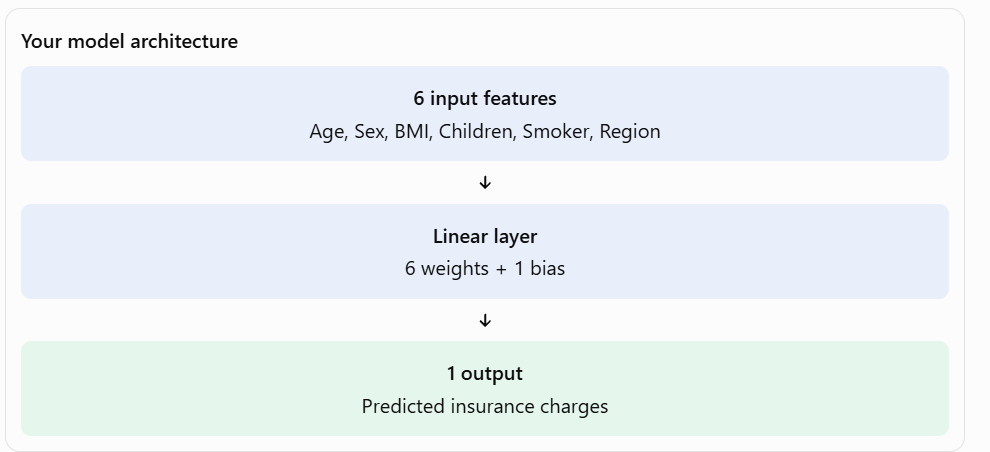

In [24]:
def evaluate(model, val_loader):
    outputs = [model.validation_step(batch) for batch in val_loader]
    return model.validation_epoch_end(outputs)

In [25]:
def fit(epochs, lr, model, train_loader, val_loader,
        opt_func=torch.optim.SGD):

    history = []

    optimizer = opt_func(model.parameters(), lr)

    for epoch in range(epochs):

        # Training phase
        for batch in train_loader:
            loss = model.training_step(batch)

            loss.backward()

            optimizer.step()

            optimizer.zero_grad()

        # Validation phase
        result = evaluate(model, val_loader)

        model.epoch_end(epoch, result, epochs)

        history.append(result)

    return history

In [26]:
result = evaluate(model, val_loader)

print(result)

{'val_loss': 432091136.0}


In [27]:
epochs = 100
lr = 1e-5

history1 = fit(epochs, lr, model, train_loader, val_loader)

Epoch [20], val_loss: 176523328.0000
Epoch [40], val_loss: 176490928.0000
Epoch [60], val_loss: 176218256.0000
Epoch [80], val_loss: 176051696.0000
Epoch [100], val_loss: 175810096.0000


In [28]:
epochs = 100
lr = 1e-5

history2 = fit(epochs, lr, model, train_loader, val_loader)

Epoch [20], val_loss: 175613616.0000
Epoch [40], val_loss: 175368368.0000
Epoch [60], val_loss: 175132336.0000
Epoch [80], val_loss: 174787504.0000
Epoch [100], val_loss: 174569712.0000


In [29]:
epochs = 100
lr = 1e-5

history3 = fit(epochs, lr, model, train_loader, val_loader)

Epoch [20], val_loss: 174253728.0000
Epoch [40], val_loss: 173997568.0000
Epoch [60], val_loss: 173673808.0000
Epoch [80], val_loss: 173434688.0000
Epoch [100], val_loss: 173135296.0000


In [30]:
epochs = 100
lr = 1e-5

history4 = fit(epochs, lr, model, train_loader, val_loader)

Epoch [20], val_loss: 172944752.0000
Epoch [40], val_loss: 172590640.0000
Epoch [60], val_loss: 172403328.0000
Epoch [80], val_loss: 172104144.0000
Epoch [100], val_loss: 171844112.0000


In [31]:
epochs = 100
lr = 1e-5

history5 = fit(epochs, lr, model, train_loader, val_loader)

Epoch [20], val_loss: 171622640.0000
Epoch [40], val_loss: 171315120.0000
Epoch [60], val_loss: 171022512.0000
Epoch [80], val_loss: 170778112.0000
Epoch [100], val_loss: 170550080.0000


In [32]:
val_loss = evaluate(model, val_loader)

print(val_loss)

{'val_loss': 170550080.0}


In [33]:
epochs = 100
lr = 1e-5

history1 = fit(epochs, lr, model, train_loader, val_loader)

Epoch [20], val_loss: 170271616.0000
Epoch [40], val_loss: 170127424.0000
Epoch [60], val_loss: 169850416.0000
Epoch [80], val_loss: 169516592.0000
Epoch [100], val_loss: 169243648.0000


In [34]:
epochs = 100
lr = 1e-6

history2 = fit(epochs, lr, model, train_loader, val_loader)

Epoch [20], val_loss: 169221248.0000
Epoch [40], val_loss: 169198576.0000
Epoch [60], val_loss: 169171776.0000
Epoch [80], val_loss: 169146048.0000
Epoch [100], val_loss: 169119600.0000


In [35]:
epochs = 100
lr = 1e-5

history3 = fit(epochs, lr, model, train_loader, val_loader)

Epoch [20], val_loss: 168875328.0000
Epoch [40], val_loss: 168686800.0000
Epoch [60], val_loss: 168362384.0000
Epoch [80], val_loss: 168090512.0000
Epoch [100], val_loss: 167821232.0000


In [36]:
epochs = 100
lr = 1e-6

history4 = fit(epochs, lr, model, train_loader, val_loader)

Epoch [20], val_loss: 167822224.0000
Epoch [40], val_loss: 167800848.0000
Epoch [60], val_loss: 167777424.0000
Epoch [80], val_loss: 167751664.0000
Epoch [100], val_loss: 167728480.0000


In [37]:
epochs = 100
lr = 1e-5

history5 = fit(epochs, lr, model, train_loader, val_loader)

Epoch [20], val_loss: 167450800.0000
Epoch [40], val_loss: 167193328.0000
Epoch [60], val_loss: 166964208.0000
Epoch [80], val_loss: 166704080.0000
Epoch [100], val_loss: 166467520.0000


In [38]:
val_loss = evaluate(model, val_loader)

print(val_loss)

{'val_loss': 166467520.0}


In [39]:
print(model)

InsuranceModel(
  (linear): Linear(in_features=6, out_features=1, bias=True)
)


In [40]:
def predict_single(input, target, model):

    inputs = input.unsqueeze(0)

    predictions = model(inputs)

    prediction = predictions[0].detach()

    print("Input:", input)
    print("Target:", target)
    print("Prediction:", prediction)

In [41]:
input, target = val_ds[0]
predict_single(input, target, model)

input, target = val_ds[10]
predict_single(input, target, model)

input, target = val_ds[23]
predict_single(input, target, model)

Input: tensor([50.0000,  0.0000, 22.8338,  2.0000,  0.0000,  2.0000])
Target: tensor([11522.2314])
Prediction: tensor([16196.4307])
Input: tensor([56.0000,  0.0000, 26.3840,  0.0000,  0.0000,  3.0000])
Target: tensor([12623.4209])
Prediction: tensor([17845.7129])
Input: tensor([52.0000,  1.0000, 31.7917,  3.0000,  0.0000,  1.0000])
Target: tensor([12869.5850])
Prediction: tensor([18998.4668])


In [42]:
final_result = evaluate(model, val_loader)

print("Final validation loss:", final_result['val_loss'])

Final validation loss: 166467520.0


In [44]:
model.eval()

total_error = 0
total_samples = 0

with torch.no_grad():
    for xb, yb in val_loader:
        predictions = model(xb)

        total_error += torch.abs(predictions - yb).sum().item()
        total_samples += yb.numel()

mae = total_error / total_samples

print("Validation MAE:", mae)

Validation MAE: 10119.180921052632


In [46]:
for i, history in enumerate(
    [history1, history2, history3, history4, history5],
    start=1
):
    print(
        f"Experiment {i}: "
        f"{history[-1]['val_loss']:.2f}"
    )

Experiment 1: 169243648.00
Experiment 2: 169119600.00
Experiment 3: 167821232.00
Experiment 4: 167728480.00
Experiment 5: 166467520.00
